# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Podcast Top Charts Dataset](https://www.kaggle.com/datasets/vedauv/what-makes-a-podcast-top-charting-5000-shows/data?select=podcast_top_charts.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('podcast_top_charts.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,podcast_id,show_name,genre,format,cadence,years_active,episodes_published,avg_episode_min,host_count,has_video,guest_fame,ad_minutes_per_ep,social_followers_k,avg_rating,review_count_k,monthly_listeners_k,top_charting
0,PD00001,Golden Run,Technology,News Brief,Biweekly,5.6,107,54,1,1,7.3,3.2,6.8,5.00,3.56,63.5,1
1,PD00002,Lost Run,History,Narrative,Weekly,1.3,44,149,2,0,2.7,6.9,12.8,4.16,0.09,10.7,0
2,PD00003,Midnight Horizon,Health,Panel,Weekly,1.2,56,27,4,0,2.7,4.4,0.3,4.47,0.15,8.2,0
3,PD00004,Iron Outpost,Music,Interview,Biweekly,0.3,4,51,2,1,6.1,7.5,19.8,4.49,0.12,8.3,0
4,PD00005,Lost Signal,Business,Panel,Weekly,5.0,247,28,4,0,3.3,0.0,29.7,4.82,5.76,172.0,1


## last Five row

In [4]:
df.tail()

,podcast_id,show_name,genre,format,cadence,years_active,episodes_published,avg_episode_min,host_count,has_video,guest_fame,ad_minutes_per_ep,social_followers_k,avg_rating,review_count_k,monthly_listeners_k,top_charting
4995,PD04996,Hollow Reign,Business,Panel,Weekly,1.2,34,51,5,1,4.2,6.9,0.6,4.56,0.34,9.8,0
4996,PD04997,Golden Vault,Sports,News Brief,Weekly,1.5,73,56,2,0,7.5,5.4,6.3,4.73,0.44,22.1,0
4997,PD04998,Shattered Horizon,Sports,Narrative,Monthly,1.6,19,34,2,0,3.4,3.0,3.5,4.82,0.21,7.6,0
4998,PD04999,Hollow Cipher,Music,News Brief,Weekly,0.3,11,31,2,0,5.9,6.5,2.0,4.72,0.17,11.3,0
4999,PD05000,Iron Empire,True Crime,Solo,Weekly,3.0,133,96,1,0,5.7,1.2,14.5,4.52,0.85,20.9,0


## Shape of our dataset

In [5]:
df.shape

(5000, 17)

## List out all columns

In [6]:
df.columns

Index(['podcast_id', 'show_name', 'genre', 'format', 'cadence', 'years_active',
       'episodes_published', 'avg_episode_min', 'host_count', 'has_video',
       'guest_fame', 'ad_minutes_per_ep', 'social_followers_k', 'avg_rating',
       'review_count_k', 'monthly_listeners_k', 'top_charting'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

podcast_id              object
show_name               object
genre                   object
format                  object
cadence                 object
years_active           float64
episodes_published       int64
avg_episode_min          int64
host_count               int64
has_video                int64
guest_fame             float64
ad_minutes_per_ep      float64
social_followers_k     float64
avg_rating             float64
review_count_k         float64
monthly_listeners_k    float64
top_charting             int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   podcast_id           5000 non-null   object 
 1   show_name            5000 non-null   object 
 2   genre                5000 non-null   object 
 3   format               5000 non-null   object 
 4   cadence              5000 non-null   object 
 5   years_active         5000 non-null   float64
 6   episodes_published   5000 non-null   int64  
 7   avg_episode_min      5000 non-null   int64  
 8   host_count           5000 non-null   int64  
 9   has_video            5000 non-null   int64  
 10  guest_fame           5000 non-null   float64
 11  ad_minutes_per_ep    5000 non-null   float64
 12  social_followers_k   5000 non-null   float64
 13  avg_rating           5000 non-null   float64
 14  review_count_k       5000 non-null   float64
 15  monthly_listeners_k  5000 non-null   f

## Check Null Value

In [9]:
df.isnull().sum()

podcast_id             0
show_name              0
genre                  0
format                 0
cadence                0
years_active           0
episodes_published     0
avg_episode_min        0
host_count             0
has_video              0
guest_fame             0
ad_minutes_per_ep      0
social_followers_k     0
avg_rating             0
review_count_k         0
monthly_listeners_k    0
top_charting           0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,years_active,episodes_published,avg_episode_min,host_count,has_video,guest_fame,ad_minutes_per_ep,social_followers_k,avg_rating,review_count_k,monthly_listeners_k,top_charting
count,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2.681740,118.787400,52.566000,1.89280,0.382200,3.998620,5.034700,11.35208,4.498710,1.054988,36.294360,0.150400
std,2.470917,230.119787,27.660873,1.16995,0.485974,2.030249,2.831675,22.69594,0.248583,1.720787,54.226571,0.357499
min,0.200000,3.000000,7.000000,1.00000,0.000000,0.000000,0.000000,0.10000,3.500000,0.010000,0.400000,0.000000
25%,0.900000,22.000000,33.000000,1.00000,0.000000,2.400000,3.000000,2.10000,4.330000,0.240000,9.375000,0.000000
50%,1.900000,54.000000,47.000000,2.00000,0.000000,3.900000,5.000000,5.00000,4.500000,0.530000,20.000000,0.000000
75%,3.600000,121.000000,65.000000,2.00000,1.000000,5.500000,7.000000,12.20000,4.670000,1.170000,41.125000,0.000000
max,14.000000,2500.000000,240.000000,5.00000,1.000000,10.000000,15.900000,777.60000,5.000000,39.850000,1236.300000,1.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

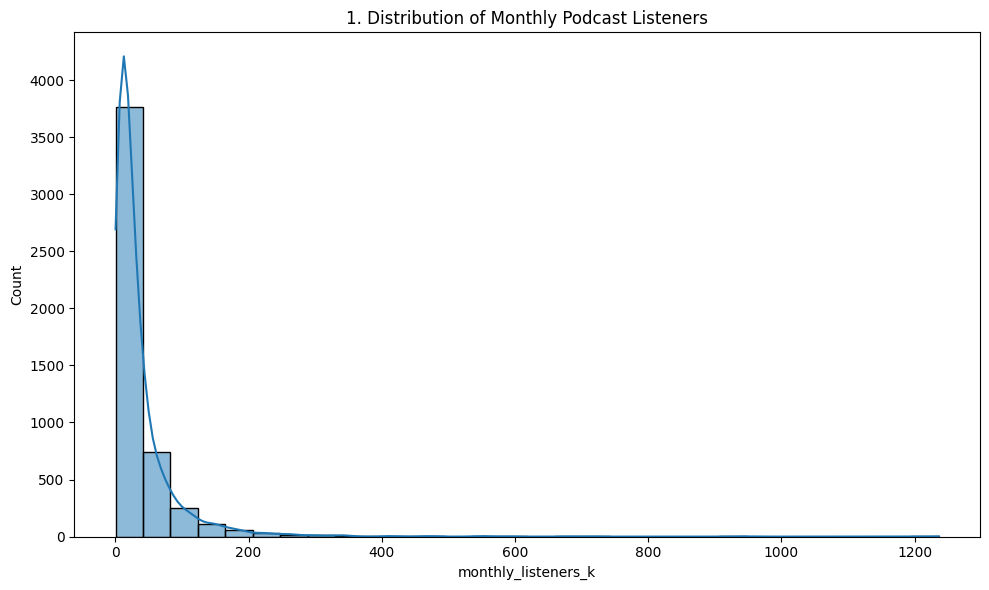

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='monthly_listeners_k', bins=30, kde=True)
plt.title(f'{plot_no}. Distribution of Monthly Podcast Listeners')
show_fig()
plot_no += 1

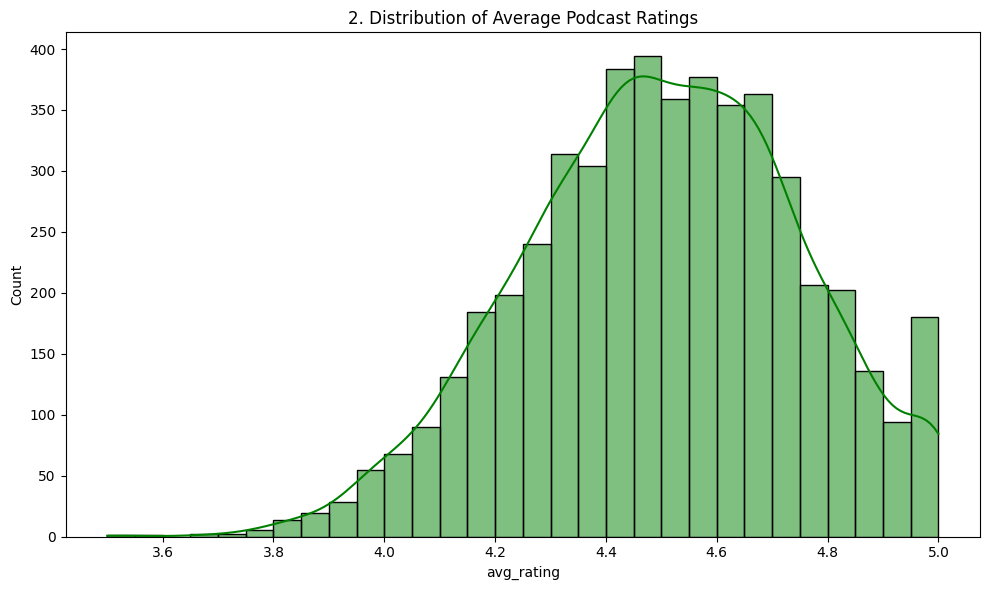

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='avg_rating', bins=30, kde=True, color='green')
plt.title(f'{plot_no}. Distribution of Average Podcast Ratings')
show_fig()
plot_no += 1

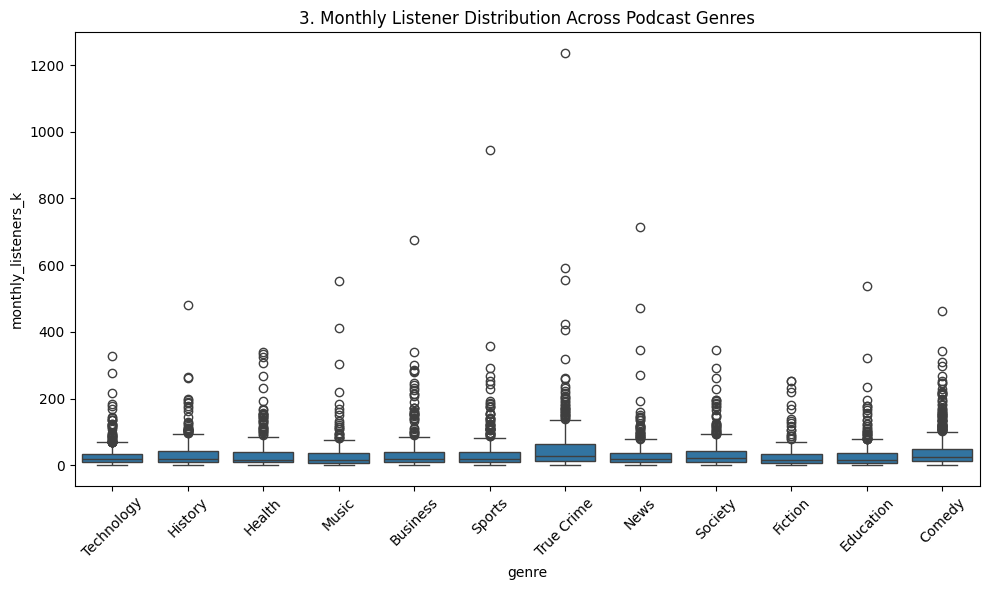

In [15]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='genre', y='monthly_listeners_k')
plt.title(f'{plot_no}. Monthly Listener Distribution Across Podcast Genres')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

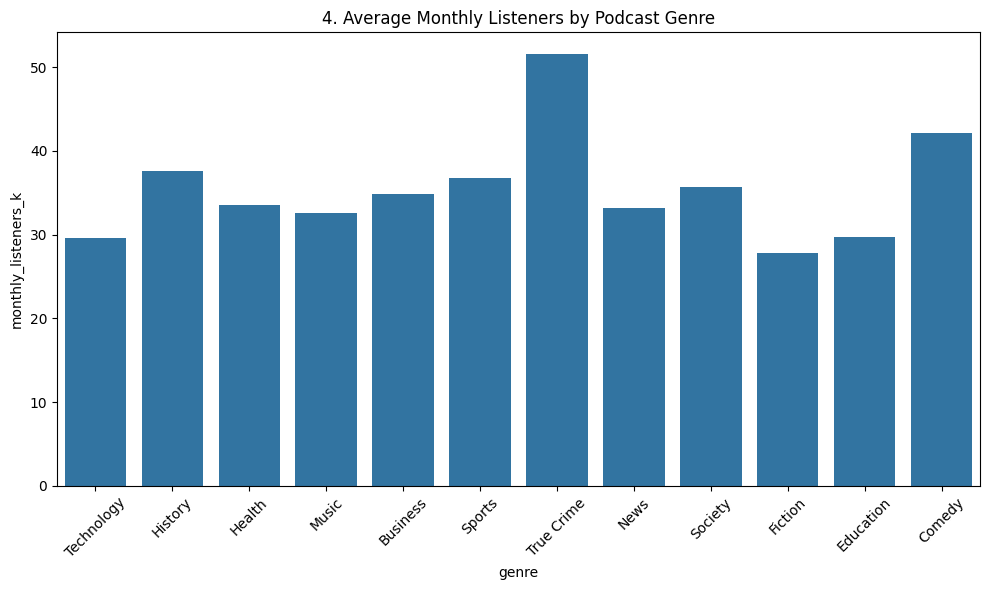

In [16]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='genre', y='monthly_listeners_k', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Average Monthly Listeners by Podcast Genre')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

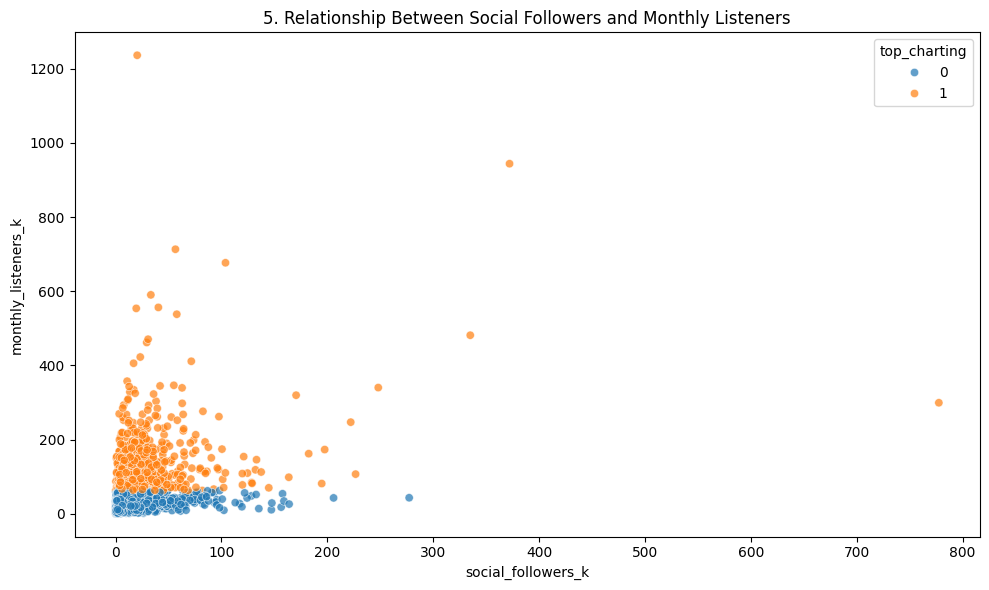

In [17]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='social_followers_k', y='monthly_listeners_k', hue='top_charting', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Social Followers and Monthly Listeners')
show_fig()
plot_no += 1

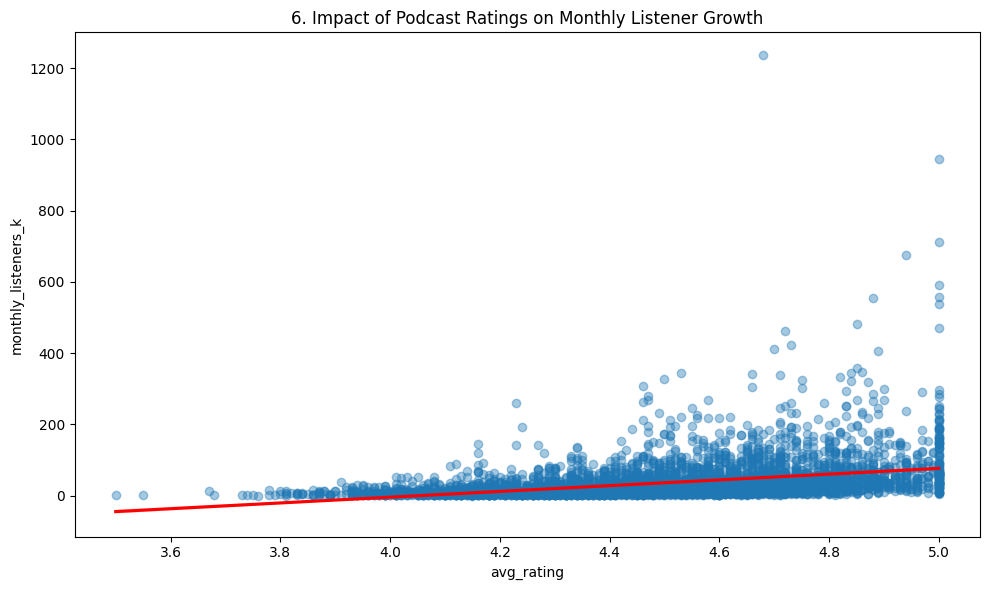

In [18]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='avg_rating', y='monthly_listeners_k', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Impact of Podcast Ratings on Monthly Listener Growth')
show_fig()
plot_no += 1

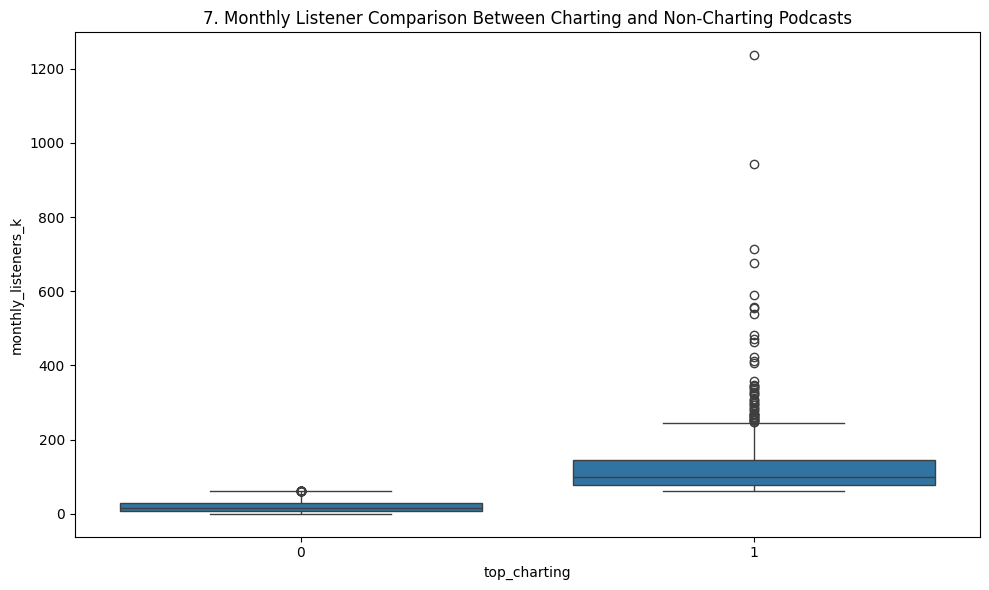

In [19]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='top_charting', y='monthly_listeners_k')
plt.title(f'{plot_no}. Monthly Listener Comparison Between Charting and Non-Charting Podcasts')
show_fig()
plot_no += 1

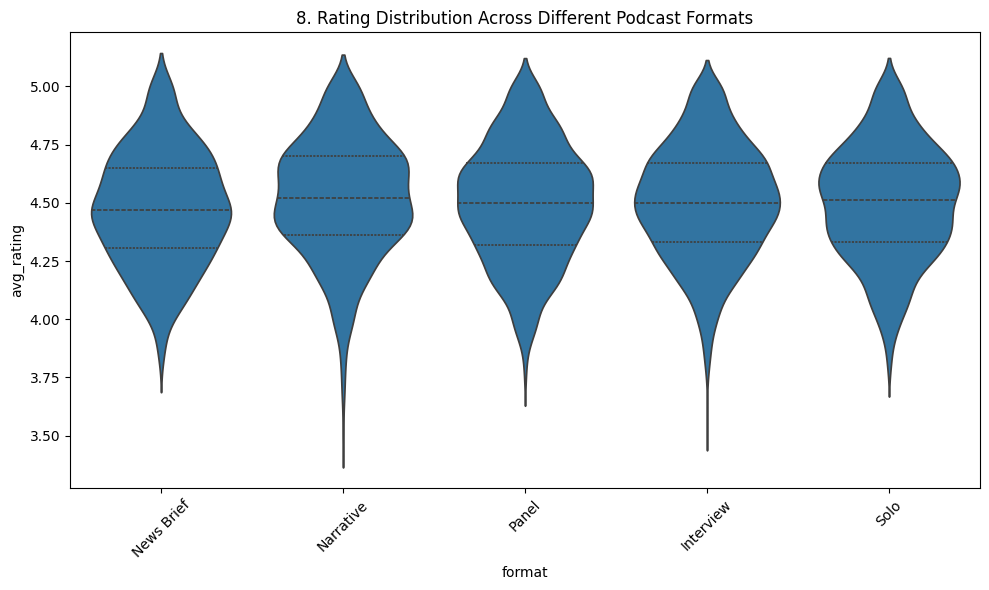

In [20]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='format', y='avg_rating', inner='quartile')
plt.title(f'{plot_no}. Rating Distribution Across Different Podcast Formats')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

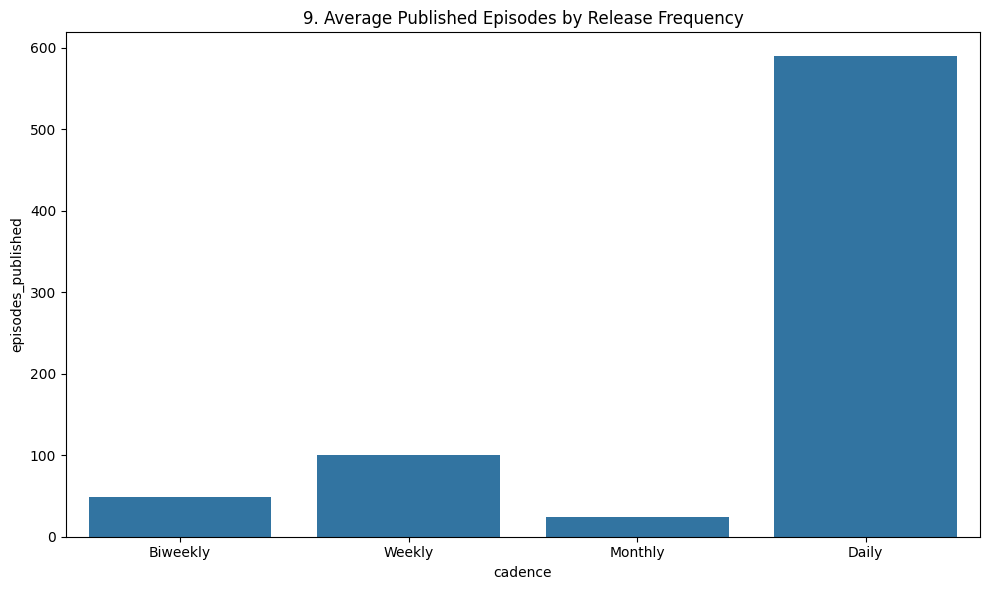

In [21]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='cadence', y='episodes_published', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Average Published Episodes by Release Frequency')
show_fig()
plot_no += 1

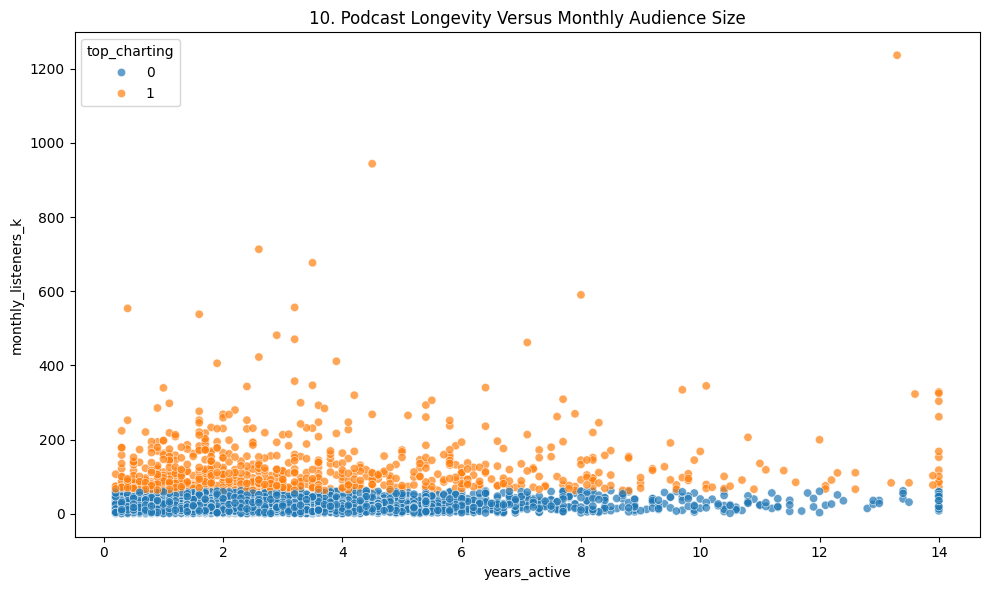

In [22]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='years_active', y='monthly_listeners_k', hue='top_charting', alpha=0.7)
plt.title(f'{plot_no}. Podcast Longevity Versus Monthly Audience Size')
show_fig()
plot_no += 1

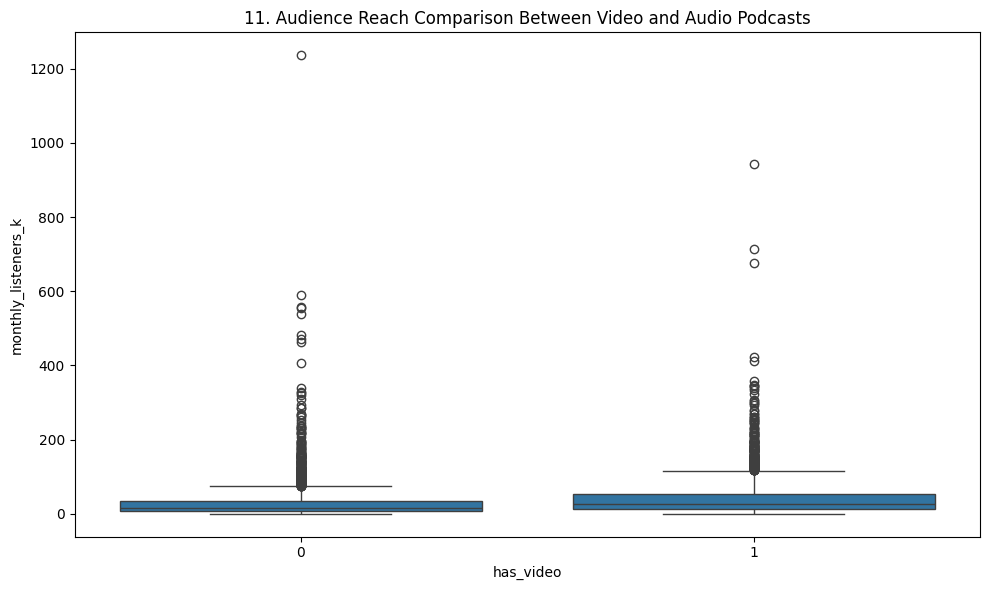

In [23]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='has_video', y='monthly_listeners_k')
plt.title(f'{plot_no}. Audience Reach Comparison Between Video and Audio Podcasts')
show_fig()
plot_no += 1

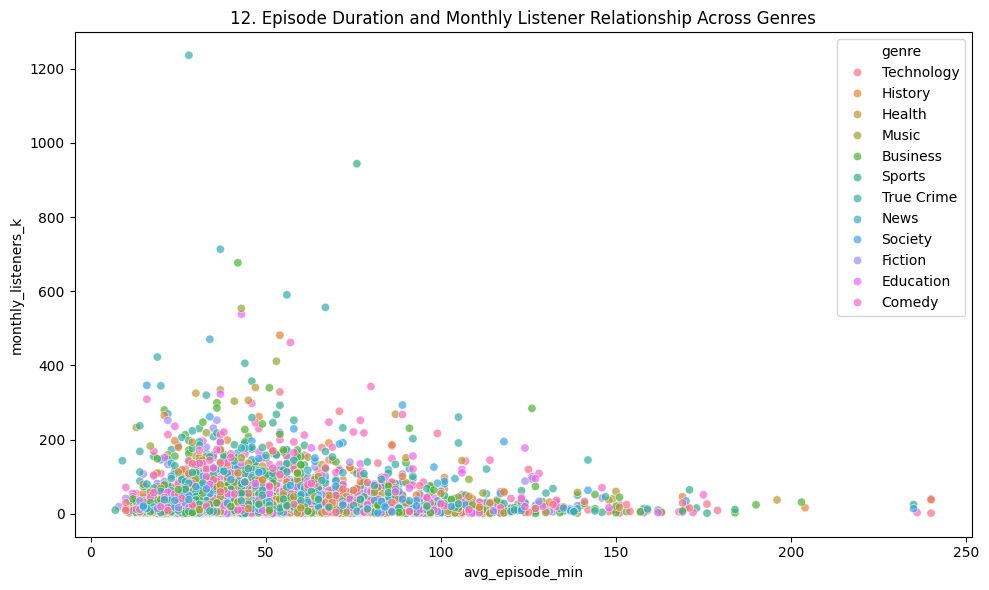

In [24]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='avg_episode_min', y='monthly_listeners_k', hue='genre', alpha=0.7)
plt.title(f'{plot_no}. Episode Duration and Monthly Listener Relationship Across Genres')
show_fig()
plot_no += 1

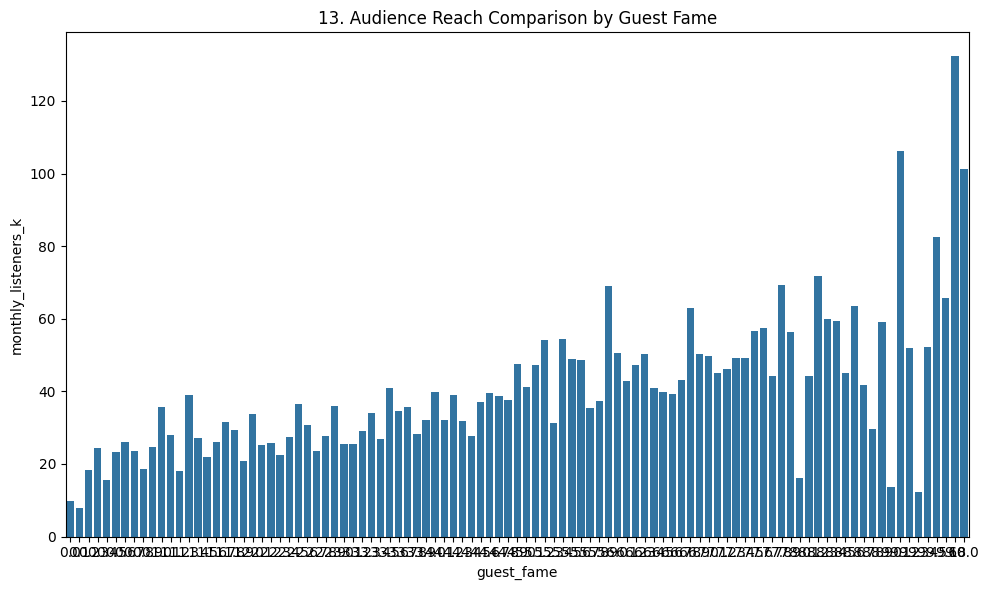

In [25]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='guest_fame', y='monthly_listeners_k', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Audience Reach Comparison by Guest Fame')
show_fig()
plot_no += 1

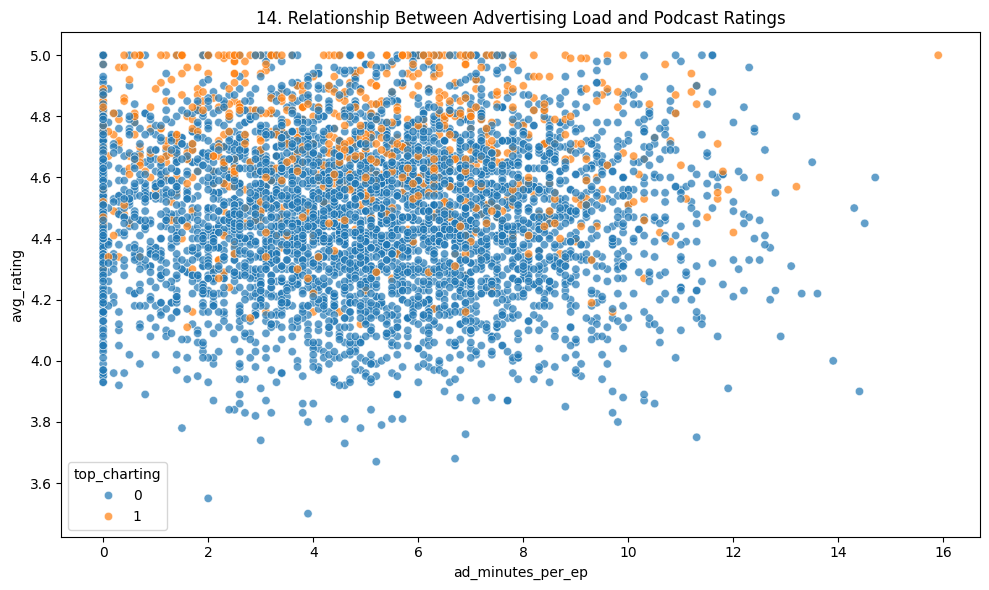

In [26]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='ad_minutes_per_ep', y='avg_rating', hue='top_charting', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Advertising Load and Podcast Ratings')
show_fig()
plot_no += 1

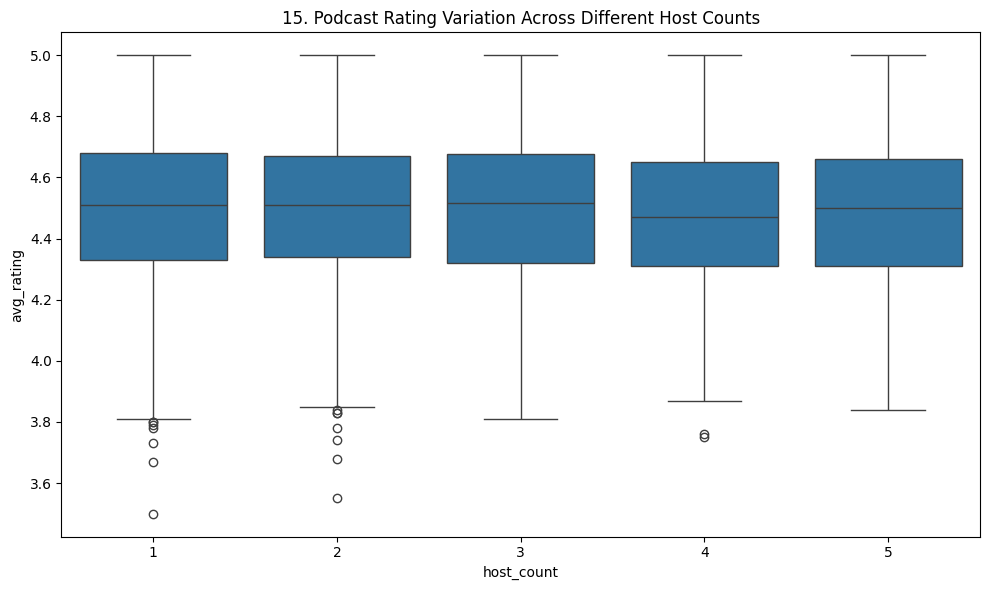

In [27]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='host_count', y='avg_rating')
plt.title(f'{plot_no}. Podcast Rating Variation Across Different Host Counts')
show_fig()
plot_no += 1

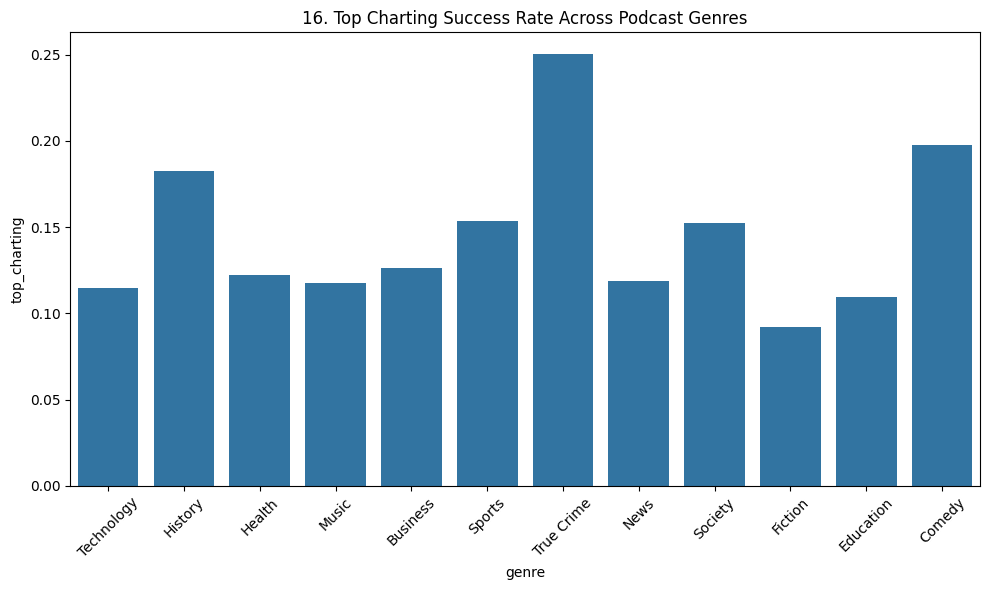

In [28]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='genre', y='top_charting', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Top Charting Success Rate Across Podcast Genres')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

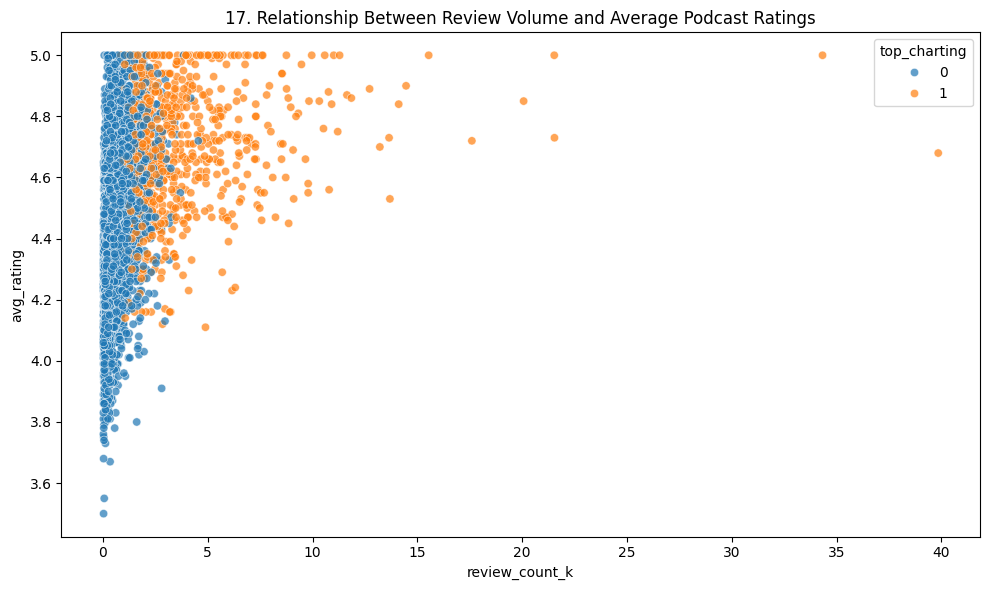

In [29]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='review_count_k', y='avg_rating', hue='top_charting', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Review Volume and Average Podcast Ratings')
show_fig()
plot_no += 1

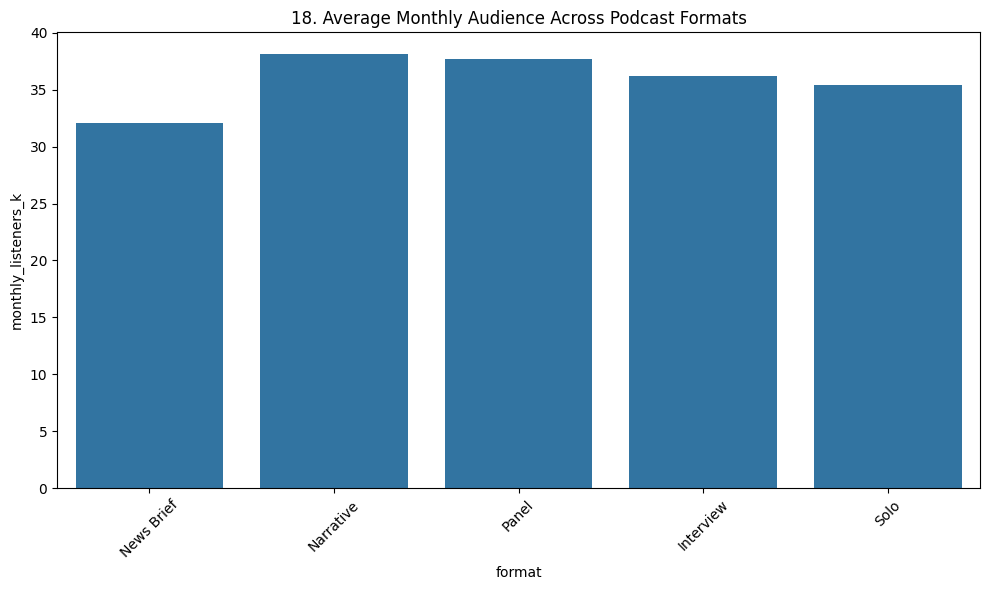

In [30]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='format', y='monthly_listeners_k', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Average Monthly Audience Across Podcast Formats')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

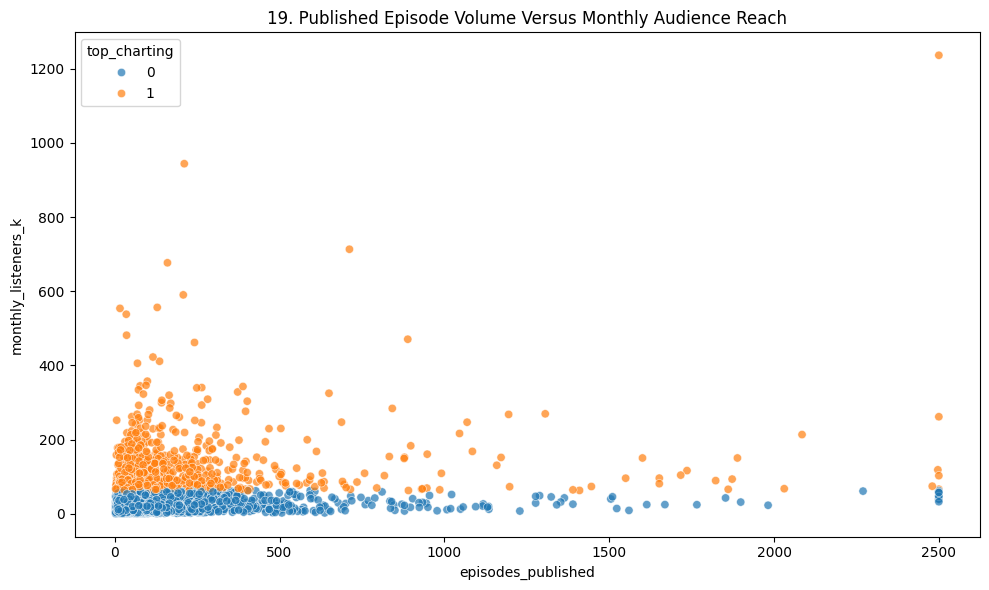

In [31]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='episodes_published', y='monthly_listeners_k', hue='top_charting', alpha=0.7)
plt.title(f'{plot_no}. Published Episode Volume Versus Monthly Audience Reach')
show_fig()
plot_no += 1

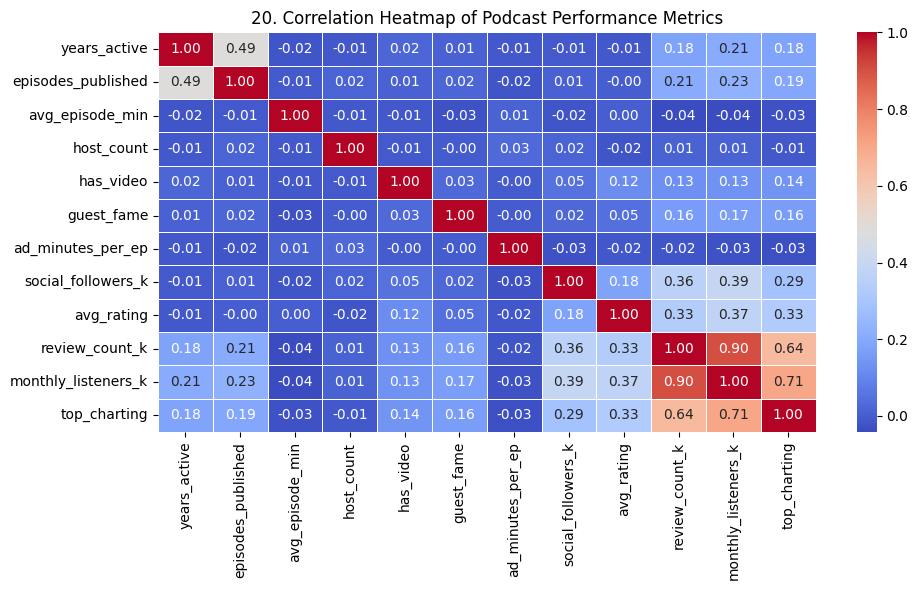

In [32]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Podcast Performance Metrics')
show_fig()
plot_no += 1

# Model Training

## Separate features and target

In [33]:
X = df.drop(columns=['top_charting', 'podcast_id', 'show_name'])
y = df['top_charting']

## Identify numerical and categorical columns

In [34]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

## Preprocess numerical and categorical features

In [35]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

## Split dataset

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## Create model pipeline

In [37]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', HistGradientBoostingClassifier(random_state=42))
])

## Tune model hyperparameters

In [38]:
params = {
    'model__learning_rate': [0.05, 0.1],
    'model__max_iter': [100, 200],
    'model__max_leaf_nodes': [15, 31],
    'model__l2_regularization': [0, 1]
}

grid = GridSearchCV(
    pipeline, params, cv=5, scoring='accuracy', n_jobs=-1
)

## Train optimized model

In [39]:
grid.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__l2_regularization': [0, 1], 'model__learning_rate': [0.05, 0.1], 'model__max_iter': [100, 200], 'model__max_leaf_nodes': [15, 31]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


## Generate predictions

In [40]:
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

## Evaluate model

In [41]:
print("Best Parameters:", grid.best_params_)
print("Training Accuracy:", best_model.score(X_train, y_train))
print("Testing Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Best Parameters: {'model__l2_regularization': 0, 'model__learning_rate': 0.05, 'model__max_iter': 100, 'model__max_leaf_nodes': 15}
Training Accuracy: 1.0
Testing Accuracy: 0.995

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       850
           1       0.98      0.99      0.98       150

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       1.00      0.99      1.00      1000



## Plot confusion matrix

<Figure size 1000x600 with 0 Axes>

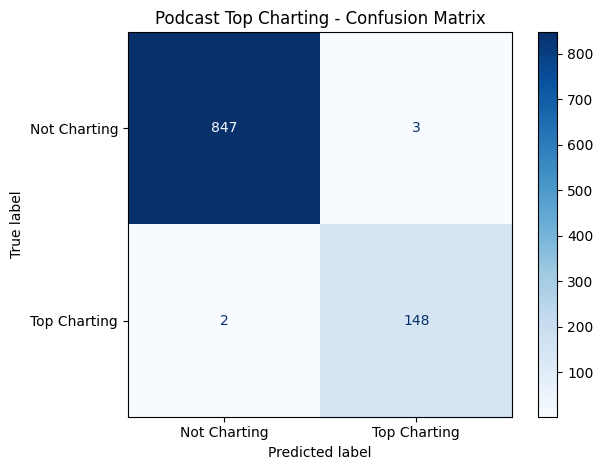

In [42]:
fig = plt.figure(figsize=(10,6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap='Blues',
    display_labels=['Not Charting', 'Top Charting'],
    values_format='d'
)
plt.title('Podcast Top Charting - Confusion Matrix')
show_fig()